# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024170240        # <-- your full roll number
NAME = "Aryan Singh"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170240   Name: Aryan Singh   Fingerprint: D54E5CDA   Tickets: 12

Ticket_ID                                                                                           Ticket_Text
      T01                                     WiFi stopped responding after resetting my password. Please help.
      T02                                                        The password has stopped syncing. Please help.
      T03                                                        Re-installing didn't help; log-in still fails!
      T04               I tried restarting the printer after restarting the system. I have tried several times!
      T05                                                   The server keeps disconnecting. Can you check this?
      T06 I keep getting logged out of the password before the assignment deadline. I have tried several times!
      T07                                  Lms has stopped syncing after resetting my password. This is urgent.
      T08            

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:
# Your code
# Q1
import pandas as pd

rows = []
for i, r in df.iterrows():
    p = process_ticket(r["Ticket_Text"])
    rows.append({"Ticket_ID": r["Ticket_ID"],
                 "Sentences": len(p["sentences"]),
                 "Tokens": len(p["tokens"]),
                 "Punctuation": len(p["punct"]),
                 "Stopwords": len(p["stops"]),
                 "Unique_Tokens": len(set(p["tokens"])),
                 "Final_Tokens": len(p["final"])})

table = pd.DataFrame(rows)
total = table.drop(columns="Ticket_ID").sum()
total["Ticket_ID"] = "TOTAL"
table = pd.concat([table, pd.DataFrame([total])], ignore_index=True)
print(table.to_string(index=False))

selected = FOCUS[0]
text = df[df["Ticket_ID"] == selected]["Ticket_Text"].iloc[0]
p = process_ticket(text)
print("\nSelected ticket:", selected)
print("Text:", text)
print("Tokens:", p["tokens"])
print("Punctuation tokens:", p["punct"])
print("Stopwords:", p["stops"])
print("Final tokens:", p["final"])

Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique_Tokens  Final_Tokens
      T01          2      11            2          2             10             7
      T02          2       9            2          2              8             5
      T03          1       9            2          1              9             6
      T04          2      16            2          6             12             8
      T05          2      10            2          4             10             4
      T06          2      19            2          8             17             9
      T07          2      13            2          5             12             6
      T08          2       8            2          1              7             5
      T09          1       9            2          2              9             5
      T10          2      12            2          4             11             6
      T11          1      11            1          4              9             6
      T12       

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*  n't and ca are not real words. They come from word_tokenize splitting contractions: can't becomes ca + n't and didn't becomes did + n't. did and do are stopwords and get removed, so only the fragments remain. it.helpdesk and thapar.edu are also fragments, left from the email address being split at @.


---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code
# Q2
import re

LONG_WORDS = r"\b[A-Za-z]{6,}\b"
NUMBERS = r"\b\d+(?:,\d{3})*(?:\.\d+)*\b"
CAPITALIZED = r"\b[A-Z][A-Za-z]*(?:[-'][A-Za-z]+)*"
VOWEL_WORDS = r"(?<![\w@./'-])[AEIOUaeiou][A-Za-z]*(?:'[A-Za-z]+)?"

EMAIL = r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+"
URL = r"(?:https?://|www\.)[\w\-./?=&%#]*[\w/]"
PHONE = r"\+91[\s-]?\d{5}[\s-]?\d{5}|\b0\d{2,4}-\d{3}-\d{4}\b"

def run_regex(lines):
    for line in lines:
        print("Text:", line)
        print("  Words > 5 letters:", re.findall(LONG_WORDS, line))
        print("  Numbers:", re.findall(NUMBERS, line))
        print("  Capitalized words:", re.findall(CAPITALIZED, line))
        print("  Words starting with a vowel:", re.findall(VOWEL_WORDS, line))
        cleaned = re.sub(EMAIL, "<EMAIL>", line)
        cleaned = re.sub(URL, "<URL>", cleaned)
        cleaned = re.sub(PHONE, "<PHONE>", cleaned)
        print("  After replacement:", cleaned)
        print()

print("===== TEST_LINES =====")
run_regex(TEST_LINES)
print("===== MY TICKETS =====")
run_regex(df["Ticket_Text"])

===== TEST_LINES =====
Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  Words > 5 letters: ['helpdesk', 'thapar', 'thapar', 'thapar']
  Numbers: []
  Capitalized words: ['Mail']
  Words starting with a vowel: ['it', 'or', 'a', 'or']
  After replacement: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>.

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  Words > 5 letters: ['Version']
  Numbers: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250']
  Capitalized words: ['Call', 'Version', 'Rs']
  Words starting with a vowel: ['or', 'is']
  After replacement: Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
  Words > 5 letters: []
  Numbers: ['5.30']
  Capitalized words: ['The']
  Words starting with a vowel: ["isn't", 'o

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*  3 of the 23 capitalized words are capitalized only because they start a sentence (The ×4, Please ×3, Can, This, Write, Only, Re-installing, Lms). The others (I, WiFi, VPN, PCs) are always capitalized.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:
# Your code
# Q3
from nltk.tokenize import RegexpTokenizer, word_tokenize

PATTERN = r"""(?x)
      (?:https?://|www\.)[\w\-./?=&%#]*[\w/]        # URLs
    | [\w.+-]+@[\w-]+(?:\.[\w-]+)+                  # email addresses
    | \+91[\s-]?\d{5}[\s-]?\d{5}                    # mobile numbers
    | \b0\d{2,4}-\d{3}-\d{4}\b                      # landline numbers
    | \d+(?:[.,]\d+)+                               # decimals and versions
    | \w+(?:[-']\w+)*                               # words, contractions, hyphenated words
    | [^\w\s]                                       # any other symbol
"""
tokenizer = RegexpTokenizer(PATTERN)

def my_tokenize(text):
    return tokenizer.tokenize(text)

def compare(lines):
    different = 0
    for line in lines:
        mine = my_tokenize(line)
        nltk_tokens = word_tokenize(line)
        print("Text:", line)
        print("  my_tokenize:  ", mine)
        print("  word_tokenize:", nltk_tokens)
        if mine != nltk_tokens:
            different += 1
            print("  Only in my_tokenize:  ", [t for t in mine if t not in nltk_tokens])
            print("  Only in word_tokenize:", [t for t in nltk_tokens if t not in mine])
        print()
    return different

print("===== TEST_LINES =====")
compare(TEST_LINES)
print("===== MY TICKETS =====")
count = compare(df["Ticket_Text"])
print("Tickets tokenized differently:", count, "out of", len(df))

===== TEST_LINES =====
Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  my_tokenize:   ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
  word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
  Only in my_tokenize:   ['it.helpdesk@thapar.edu', 'a.b-c@dept.univ.ac.in', 'https://lms.thapar.edu/help']
  Only in word_tokenize: ['it.helpdesk', '@', 'thapar.edu', 'a.b-c', '@', 'dept.univ.ac.in', 'https', ':', '//lms.thapar.edu/help']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  my_tokenize:   ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', 

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*  4 of my 12 tickets are tokenized differently (T03, T09, T10, T11).

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:
# Your code
# Q4
import nltk
import pandas as pd
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp = RegexpStemmer("ing$|ed$", min=5)
lemmatizer = WordNetLemmatizer()

def wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

# POS tags are taken from the full ticket so each word is tagged in context
pos_of = {}
for text in df["Ticket_Text"]:
    p = process_ticket(text)
    for word, tag in nltk.pos_tag(p["tokens"]):
        if word in p["final"] and word not in pos_of:
            pos_of[word] = tag

unique_final = sorted(pos_of)
print("Unique final tokens:", len(unique_final))

rows = []
for w in unique_final:
    rows.append({"Word": w,
                 "POS": pos_of[w],
                 "Porter": porter.stem(w),
                 "Lancaster": lancaster.stem(w),
                 "Regexp": regexp.stem(w),
                 "Lemma": lemmatizer.lemmatize(w, wordnet_pos(pos_of[w]))})

stem_table = pd.DataFrame(rows)
cols = ["Porter", "Lancaster", "Regexp", "Lemma"]
differ = stem_table[stem_table[cols].nunique(axis=1) > 1]
print("Words where the outputs differ:", len(differ))
print(differ.to_string(index=False))

Unique final tokens: 49
Words where the outputs differ: 26
         Word POS    Porter     Lancaster     Regexp         Lemma
     anything  NN     anyth         anyth      anyth      anything
   assignment  JJ    assign        assign assignment    assignment
       change  VB     chang         chang     change        change
      changed VBD     chang         chang      chang        change
     deadline  NN   deadlin       deadlin   deadline      deadline
        fails VBZ      fail          fail      fails          fail
      getting VBG       get           get       gett           get
        hours NNS      hour          hour      hours          hour
        keeps VBZ      keep          keep      keeps          keep
          lms  NN        lm           lms        lms            lm
       logged VBD       log           log       logg           log
          pcs NNS        pc           pcs        pcs            pc
       please  VB     pleas         pleas     please        please
   

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*  Over-stemming: Porter turns several into sever, a different word. Under-stemming: the Regexp stemmer leaves keeps unchanged, so keep and keeps stay as two separate words.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

              Set  Total  Unique   TTR
    S1 all tokens    137      74 0.540
S2 no punctuation    115      69 0.600
  S3 final tokens     73      49 0.671
  S4 Porter stems     73      47 0.644

Top 10 words of S1: [('.', 16), ('the', 8), ('i', 7), ('stopped', 4), ('after', 4), ('password', 4), ('help', 4), ("n't", 4), ('please', 3), ('!', 3)]
Top 10 words of S3: [('stopped', 4), ('password', 4), ('help', 4), ("n't", 4), ('please', 3), ('tried', 3), ('responding', 2), ('resetting', 2), ('syncing', 2), ('restarting', 2)]

Top 5 bigrams of S1: [(('.', 'please'), 3), (('please', 'help'), 3), (('help', '.'), 3), (('.', 'i'), 3), (('stopped', 'responding'), 2)]
Top 5 bigrams of S3: [(('please', 'help'), 3), (('stopped', 'responding'), 2), (('resetting', 'password'), 2), (('stopped', 'syncing'), 2), (('tried', 'several'), 2)]


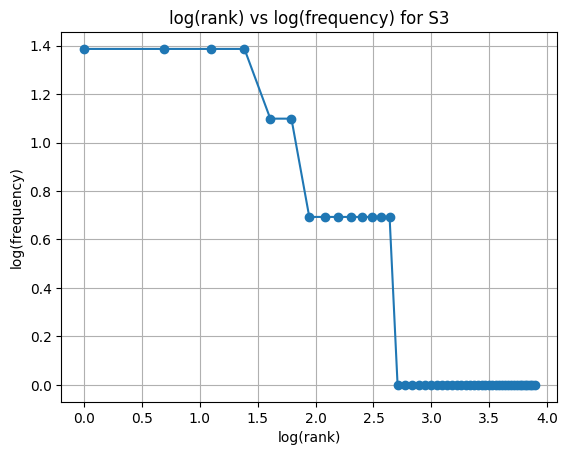

In [ ]:
# Your code
# Q5
import math
from collections import Counter
import matplotlib.pyplot as plt
import pandas as pd
from nltk import bigrams
from nltk.stem import PorterStemmer

porter = PorterStemmer()
S1, S2, S3 = [], [], []
bigrams_S1, bigrams_S3 = [], []
for text in df["Ticket_Text"]:
    p = process_ticket(text)
    S1 += p["tokens"]
    S2 += [t for t in p["tokens"] if not is_punct(t)]
    S3 += p["final"]
    bigrams_S1 += list(bigrams(p["tokens"]))
    bigrams_S3 += list(bigrams(p["final"]))
S4 = [porter.stem(t) for t in S3]

stats = []
for name, tokens in [("S1 all tokens", S1), ("S2 no punctuation", S2),
                     ("S3 final tokens", S3), ("S4 Porter stems", S4)]:
    stats.append({"Set": name, "Total": len(tokens), "Unique": len(set(tokens)),
                  "TTR": round(len(set(tokens)) / len(tokens), 3)})
print(pd.DataFrame(stats).to_string(index=False))

print("\nTop 10 words of S1:", Counter(S1).most_common(10))
print("Top 10 words of S3:", Counter(S3).most_common(10))

print("\nTop 5 bigrams of S1:", Counter(bigrams_S1).most_common(5))
print("Top 5 bigrams of S3:", Counter(bigrams_S3).most_common(5))

freqs = sorted(Counter(S3).values(), reverse=True)
ranks = range(1, len(freqs) + 1)
plt.plot([math.log(r) for r in ranks], [math.log(f) for f in freqs], marker="o")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("log(rank) vs log(frequency) for S3")
plt.grid(True)
plt.show()

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR rises from 0.540 (S1) to 0.600 (S2) to 0.671 (S3) because removing punctuation and stopwords takes out the most repeated tokens (. appears 16 times, the 8 times). It drops to 0.644 in S4 because stemming merges words like keep/keeps and change/changed, so unique tokens fall from 49 to 47 while the total stays at 73.